# 04 — Day 4 Evaluation: TRILLsson

**Standalone by design:** this notebook duplicates a handful of reusable pieces from `02_train_evaluate.ipynb` (the candidate/pipeline builder, `score_fn`, `best_threshold`, and the nested LOSO -> GroupKFold(6) loop itself) rather than depending on that notebook's kernel state, so it can run independently on a separate Kaggle account/session — see the conversation with the assistant and `PROJECT_PLAN.md` for why. Same logic, same leak-free asserts, same per-fold inner-CV threshold selection as every other day's evaluation in this project.

**What this evaluates:** TRILLsson's 1024-dim embedding, **isolated** — no PCA, no session-fusion combined in yet, matching how Days 2-3 tested their embeddings (one variable at a time). If TRILLsson looks like a genuine win here, combining it with Day 1's PCA / session-fusion tricks becomes a Day 6 candidate.

**Inputs needed (Kaggle "Add Input"):**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **`04_features_trillsson`**'s notebook output — for `trillsson.parquet`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
TRILLSSON_PARQUET = next(Path("/kaggle/input").rglob("trillsson.parquet"))

print(f"LABELS_CSV        = {LABELS_CSV}")
print(f"TRILLSSON_PARQUET = {TRILLSSON_PARQUET}")

LABELS_CSV        = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
TRILLSSON_PARQUET = /kaggle/input/notebooks/tapudatta/day4-features-trillsson/features/trillsson.parquet


## 1. Load & Merge

In [2]:
labels = pd.read_csv(LABELS_CSV)
embeddings = pd.read_parquet(TRILLSSON_PARQUET)

df = labels.merge(embeddings, on="filename", how="inner")
assert len(df) == len(labels) == 280, f"expected 280 rows after merge, got {len(df)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df["y"] = df["label"].map(LABEL_MAP)
assert df["y"].isna().sum() == 0, "unmapped label value found"

emb_cols = [c for c in df.columns if c.startswith("emb_")]
X = df[emb_cols].to_numpy()
y = df["y"].to_numpy()
groups = df["participant_id"].to_numpy()

print(f"X: {X.shape}, y: {y.shape}, participants: {len(np.unique(groups))}")

X: (280, 1024), y: (280,), participants: 14


## 2. Candidates & Nested CV (duplicated from `02_train_evaluate.ipynb`)

Same 10 candidates (2 model types x 5 `C` values), same `StandardScaler`-inside-the-pipeline discipline, same outer-LOSO -> inner-`GroupKFold(6)` -> per-fold inner-CV threshold algorithm, same leak-free asserts as sections 2-3 of `02_train_evaluate.ipynb`. Copied here verbatim rather than imported, since this notebook has no shared kernel with that one.

In [3]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (f"{name}_C={c}", build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    """Threshold maximizing balanced accuracy over a set of (score, label) pairs."""
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [4]:
def nested_loso_cv(X, y, groups, n_inner_splits=6):
    """Duplicated from 02_train_evaluate.ipynb's nested_loso_cv_variant (section 11) --
    same outer-LOSO -> inner-GroupKFold(6) -> per-fold inner-CV threshold algorithm
    and the same leak-free asserts."""
    participants = np.unique(groups)
    oof_scores = np.zeros(len(y), dtype=float)
    oof_preds = np.zeros(len(y), dtype=int)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = groups == test_participant
        outer_train_mask = ~outer_test_mask
        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        pooled_inner_scores = np.concatenate(cand_scores[best_i])
        pooled_inner_labels = np.concatenate(cand_labels[best_i])
        threshold = best_threshold(pooled_inner_scores, pooled_inner_labels)

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[outer_test_mask] = test_scores
        oof_preds[outer_test_mask] = (test_scores >= threshold).astype(int)

        fold_records.append({
            "test_participant": test_participant,
            "n_test": int(outer_test_mask.sum()),
            "chosen_candidate": best_label,
            "inner_cv_auc": mean_aucs[best_i],
            "threshold": threshold,
        })

    print(f"Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    return oof_scores, oof_preds, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    """Duplicated from 02_train_evaluate.ipynb's bootstrap_auc_ci_arrays."""
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}

    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))

    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)

## 3. Run & Compare

In [5]:
oof_scores, oof_preds, fold_info = nested_loso_cv(X, y, groups)

pooled_auc = roc_auc_score(y, oof_scores)
balanced_acc = balanced_accuracy_score(y, oof_preds)
f1 = f1_score(y, oof_preds)
ci_lo, ci_hi, _ = bootstrap_auc_ci(groups, y, oof_scores)

print(f"TRILLsson pooled ROC-AUC: {pooled_auc:.3f}  (95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")
print(f"Balanced accuracy: {balanced_acc:.3f}   F1: {f1:.3f}")
fold_info

Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
TRILLsson pooled ROC-AUC: 0.590  (95% CI: [0.535, 0.651])
Balanced accuracy: 0.573   F1: 0.541


,test_participant,n_test,chosen_candidate,inner_cv_auc,threshold
0,P-33B7FA2A,6,linsvc_C=0.01,0.644521,-1.202623
1,P-4B5527A7,21,linsvc_C=0.01,0.609678,0.112708
2,P-4F8CDB03,20,linsvc_C=0.01,0.621903,-1.211280
3,P-57C20427,42,linsvc_C=1.0,0.592031,1.246036
4,P-5AE2B073,6,linsvc_C=0.01,0.641932,0.848241
5,P-66395191,21,linsvc_C=0.01,0.637522,-2.507153
6,P-7DB1F098,42,logreg_C=0.1,0.626735,0.823474
7,P-87C2E2A3,21,logreg_C=0.001,0.609867,0.553672
8,P-8A4B73A3,11,linsvc_C=0.01,0.594411,-2.316030
9,P-B116746A,12,linsvc_C=0.01,0.618022,-1.207134


                       variant      auc    ci_lo    ci_hi
  Baseline (wav2vec2 layer 12) 0.542000 0.466000 0.621000
                     Day 1 PCA 0.559000 0.509000 0.625000
          Day 1 session-fusion 0.570000 0.483000 0.695000
Day 2 best layer (wav2vec2 L7) 0.581000 0.507000 0.634000
 Day 3 best layer (HuBERT L12) 0.611000 0.551000 0.683000
               Day 4 TRILLsson 0.590353 0.535279 0.650966

Bar to beat: Day 3's HuBERT layer 12 (AUC 0.611, CI [0.551, 0.683]) is the current leading candidate -- the first result so far whose CI lower bound clears 0.5 by a comfortable margin rather than a hair's width.


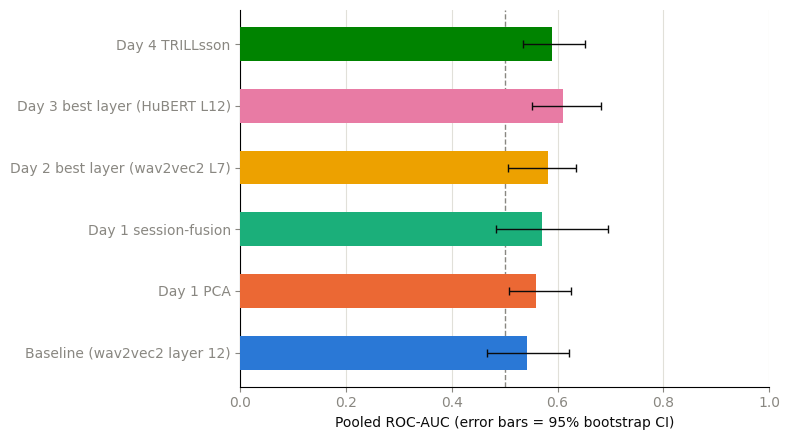

In [6]:
# Reference numbers hardcoded from PROJECT_PLAN.md's logged results so far, since this
# notebook runs standalone with no access to the other notebooks' kernel state.
reference = pd.DataFrame([
    {"variant": "Baseline (wav2vec2 layer 12)", "auc": 0.542, "ci_lo": 0.466, "ci_hi": 0.621},
    {"variant": "Day 1 PCA", "auc": 0.559, "ci_lo": 0.509, "ci_hi": 0.625},
    {"variant": "Day 1 session-fusion", "auc": 0.570, "ci_lo": 0.483, "ci_hi": 0.695},
    {"variant": "Day 2 best layer (wav2vec2 L7)", "auc": 0.581, "ci_lo": 0.507, "ci_hi": 0.634},
    {"variant": "Day 3 best layer (HuBERT L12)", "auc": 0.611, "ci_lo": 0.551, "ci_hi": 0.683},
    {"variant": "Day 4 TRILLsson", "auc": pooled_auc, "ci_lo": ci_lo, "ci_hi": ci_hi},
])
print(reference.to_string(index=False))
print("\nBar to beat: Day 3's HuBERT layer 12 (AUC 0.611, CI [0.551, 0.683]) is the current "
      "leading candidate -- the first result so far whose CI lower bound clears 0.5 by a "
      "comfortable margin rather than a hair's width.")

DAY4_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 4.5))
y_pos = np.arange(len(reference))
ax.barh(y_pos, reference["auc"], color=DAY4_COLORS[: len(reference)], height=0.55, zorder=3)
ax.errorbar(
    reference["auc"], y_pos,
    xerr=[reference["auc"] - reference["ci_lo"], reference["ci_hi"] - reference["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(reference["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## How to read Day 4's results

Same checkpoint discipline as every prior day: a clear, non-marginal win (CI lower bound comfortably above 0.5, or a point estimate consistently ahead of every wav2vec2/HuBERT variant tried) makes TRILLsson the base embedding for Day 5 (data augmentation) and Day 6 (combining winning techniques) onward. Day 3 has already cleared that bar once (HuBERT layer 12, AUC 0.611, CI [0.551, 0.683]) -- the bar to beat here isn't just "above baseline," it's "above HuBERT L12." A result similar to what's already logged (but below HuBERT L12) means HuBERT stays the leading candidate; a result below all of them means the pretraining objective HuBERT uses is still the deciding factor found so far.

Update `PROJECT_PLAN.md`'s Improvement plan with today's numbers before moving to Day 5. If HuBERT L12 remains the leader, its result is not yet confirmed with a permutation test (Days 1-3 deliberately skipped per-variant permutation tests to save compute) -- worth running one before treating it as final.